In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)


from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("/Users/subhadyutirath/Documents/Manufacturing/data/processed/engineered_data.csv")

In [3]:
type_encoder = LabelEncoder()

df["Type"] = type_encoder.fit_transform(df["Type"])

In [4]:
df["Type"].unique()

array([2, 1, 0])

In [5]:
failure_encoder = LabelEncoder()

df["Failure_Type"] = failure_encoder.fit_transform(df["Failure_Type"])


In [6]:
df["Failure_Type"].unique()

array([1, 3, 5, 2, 4, 0])

In [7]:
X = df.drop(columns=["Failure_Type"])

y = df["Failure_Type"]

In [8]:
df.columns = (
    df.columns
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace("<", "", regex=False)
    .str.replace(">", "", regex=False)
    .str.replace(" ", "_")
)

In [9]:
df.columns

Index(['Type', 'Air_temperature_K', 'Process_temperature_K',
       'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Failure_Type',
       'Temp_Diff', 'Mechanical_Power', 'Wear_Rate', 'Thermal_Stress',
       'Wear_Torque'],
      dtype='str')

In [10]:
X = df.drop(columns=["Failure_Type"])

y = df["Failure_Type"]

In [11]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)

In [12]:
smote = SMOTE(
    random_state=42,
    k_neighbors=3
)

X_train_smote, y_train_smote = (
    smote.fit_resample(
        X_train,
        y_train
    )
)

In [13]:
pd.Series(y_train_smote).value_counts()

Failure_Type
1    7722
3    7722
2    7722
0    7722
5    7722
4    7722
Name: count, dtype: int64

In [14]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    objective="multi:softmax",
    num_class=6,
    random_state=42
)

In [15]:
X_train_smote.columns

Index(['Type', 'Air_temperature_K', 'Process_temperature_K',
       'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temp_Diff',
       'Mechanical_Power', 'Wear_Rate', 'Thermal_Stress', 'Wear_Torque'],
      dtype='str')

In [16]:
xgb.fit(X_train_smote,y_train_smote)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [17]:
y_pred = xgb.predict(X_test)

In [18]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print(
    f"Accuracy: {accuracy:.4f}"
)

print(
    f"Macro F1: {macro_f1:.4f}"
)

Accuracy: 0.9765
Macro F1: 0.6468


In [19]:
print(failure_encoder.classes_)

['Heat Dissipation Failure' 'No Failure' 'Overstrain Failure'
 'Power Failure' 'Random Failure' 'Tool Wear Failure']


In [20]:
target_names = [
    "Heat Dissipation Failure",
    "No Failure",
    "Overstrain Failure",
    "Power Failure",
    "Random Failure",
    "Tool Wear Failure"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_names
    )
)

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.92      0.96      0.94        23
              No Failure       0.99      0.98      0.99      1930
      Overstrain Failure       0.73      1.00      0.84        16
           Power Failure       1.00      0.94      0.97        18
          Random Failure       0.00      0.00      0.00         4
       Tool Wear Failure       0.11      0.22      0.14         9

                accuracy                           0.98      2000
               macro avg       0.62      0.68      0.65      2000
            weighted avg       0.99      0.98      0.98      2000



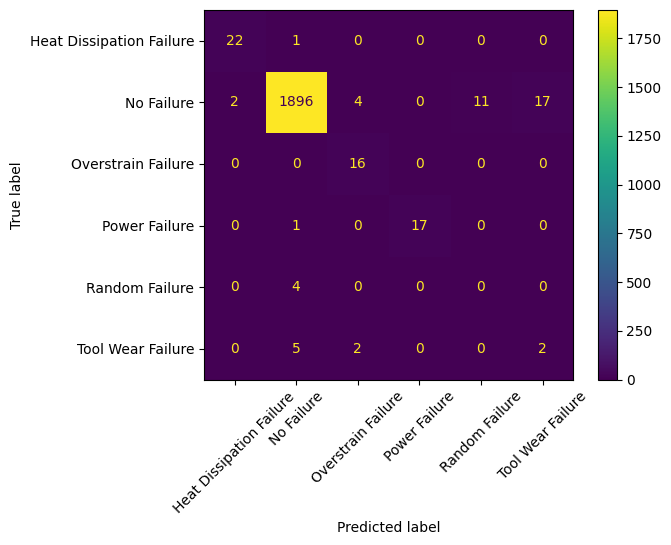

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
).plot(
    xticks_rotation=45
)

In [22]:
import joblib
joblib.dump(
    xgb,
    "/Users/subhadyutirath/Documents/Manufacturing/models/multiclass_xgb.pkl"
)

['/Users/subhadyutirath/Documents/Manufacturing/models/multiclass_xgb.pkl']